# Accuracy and latency

Compare the selectors on the answers and frame times recorded by [04_01](04_01_run_vlm.ipynb).
A condition is a method and a requested fraction of rows. `Dense` uses every row.

In [1]:
from scipy.stats import bootstrap

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

## 1. Data

`answers.csv` has one row per question and condition; `correct` says whether the answer was right.
`frame_times.csv` has one row per recorded frame and condition, with times in ms.

In [2]:
answers     = pd.read_csv("answers.csv")
frame_times = pd.read_csv("frame_times.csv")

## 2. Intervals

Every interval below is a 95% BCa bootstrap with 10,000 resamples, as in the paper.

In [3]:
def interval(values, statistic):
    """Return the 95% BCa bootstrap interval of a statistic: (low, high)."""

    result = bootstrap(
        (values,),
        statistic,
        confidence_level = 0.95,
        n_resamples      = 10_000,
        method           = "BCa",
        rng              = 0,
    )

    return result.confidence_interval.low, result.confidence_interval.high

## 3. Accuracy

Accuracy is the percentage of right answers of a condition.

In [4]:
records = []

for (method, fraction), rows in answers.groupby(["method", "fraction"], sort=False):
    scores    = 100.0 * rows.correct.to_numpy()
    low, high = interval(scores, np.mean)

    records.append({
        "method"        : method,
        "fraction"      : fraction,
        "accuracy"      : scores.mean(),
        "accuracy_low"  : low,
        "accuracy_high" : high,
    })

accuracy = pd.DataFrame(records)
accuracy = accuracy.set_index(["method", "fraction"])

## 4. Time per frame

For one frame, `selection_ms` is the time the selectors of all projections take
and `io_ms` the time to read the selected rows from flash.
Their sum, `load_ms`, is how long the frame waits for its weights.
Take the median of each over the recorded frames.

In [5]:
frame_times["load_ms"] = frame_times.selection_ms + frame_times.io_ms

In [6]:
records = []

for (method, fraction), rows in frame_times.groupby(["method", "fraction"], sort=False):
    low, high = interval(rows.load_ms.to_numpy(), np.median)

    records.append({
        "method"       : method,
        "fraction"     : fraction,
        "selection_ms" : rows.selection_ms.median(),
        "io_ms"        : rows.io_ms.median(),
        "load_ms"      : rows.load_ms.median(),
        "load_low"     : low,
        "load_high"    : high,
    })

latency = pd.DataFrame(records)
latency = latency.set_index(["method", "fraction"])

## 5. Summary

In [7]:
summary = accuracy.join(latency)
summary.round(1)

accuracy  accuracy_low  accuracy_high  selection_ms  \
method       fraction                                                        
Dense        1.0           52.2          47.3           57.0           1.0   
Top-R        0.3           43.5          38.6           48.3          14.7   
             0.5           49.1          44.2           54.0          14.7   
             0.7           50.9          46.0           55.8          14.6   
Paper greedy 0.3           32.0          27.4           36.8          70.4   
             0.5           39.1          34.5           44.2          74.2   
             0.7           48.1          43.2           52.9          90.7   
Tiles        0.3           32.5          27.9           37.1           2.0   
             0.5           39.6          35.0           44.8           1.9   
             0.7           45.3          40.4           50.4           1.9   

                       io_ms  load_ms  load_low  load_high  
method       fraction                                       
Dense        1.0       153.3    154.2     153.6      154.5  
Top-R        0.3       607.0    621.9     620.0      623.6  
             0.5       740.3    755.0     752.3      757.9  
             0.7       649.4    664.1     660.6      666.2  
Paper greedy 0.3        78.4    150.7     146.1      153.3  
             0.5       117.3    191.1     189.8      193.6  
             0.7       180.0    270.7     268.8      272.7  
Tiles        0.3        90.6     92.6      91.2       93.1  
             0.5       127.5    129.4     128.8      130.0  
             0.7       166.5    168.7     166.9      169.8

## 6. Plot

Each line connects the three fractions of one method.
Vertical bars are the accuracy intervals; the label at one end of a bar gives the fraction.
The dotted lines cross at `Dense`: points to their right take longer than reading every row.

Left: read time only. Right: selection and read time. The time axes are logarithmic.

In [8]:
colors = {
    "Top-R"        : "#2a78d6",
    "Paper greedy" : "#eb6834",
    "Tiles"        : "#1baf7a",
}

markers = {
    "Top-R"        : "o",
    "Paper greedy" : "s",
    "Tiles"        : "^",
}

# The fraction label of a point sits at one end of its accuracy interval:
# (end, vertical alignment, points up from that end).
# Paper and Tiles lie close together, so their labels take opposite ends.
anchors = {
    "Top-R"        : ("accuracy_high", "bottom",  3),
    "Paper greedy" : ("accuracy_high", "bottom",  3),
    "Tiles"        : ("accuracy_low",  "top",    -3),
}

In [9]:
def draw_dense(ax, column):
    dense = summary.loc[("Dense", 1.0)]

    ax.axvline(dense[column],  color="gray", linestyle=":", linewidth=1)
    ax.axhline(dense.accuracy, color="gray", linestyle=":", linewidth=1)

    ax.plot(
        dense[column],
        dense.accuracy,
        label = "Dense",

        color     = "black",
        linestyle = "none",
        marker    = "D",
    )

In [10]:
def draw_method(ax, column, method):
    rows  = summary.loc[method]
    below = rows.accuracy - rows.accuracy_low
    above = rows.accuracy_high - rows.accuracy

    ax.errorbar(
        rows[column],
        rows.accuracy,
        yerr  = [below, above],
        label = method,

        color      = colors[method],
        marker     = markers[method],
        markersize = 8,
        linewidth  = 2,
        capsize    = 3,
    )

    # Fraction labels
    end, va, shift = anchors[method]

    for fraction, row in rows.iterrows():
        ax.annotate(
            f"{fraction:.0%}",
            (row[column], row[end]),
            xytext     = (0, shift),
            textcoords = "offset points",
            ha         = "center",
            va         = va,
            color      = "dimgray",
            fontsize   = 8,
        )

In [11]:
TICKS = [100, 200, 400, 800]  # Ticks of the time axes (ms)

def draw_panel(ax, column, label):
    draw_dense(ax, column)

    for method in colors:
        draw_method(ax, column, method)

    ax.set(
        xscale = "log",
        xlabel = label,
    )

    # Plain numbers at the ticks instead of powers of ten
    ax.set_xticks(TICKS, labels=TICKS)
    ax.minorticks_off()

    # Room for the fraction labels
    ax.margins(y=0.08)

    ax.grid(color="gainsboro", linewidth=0.6)

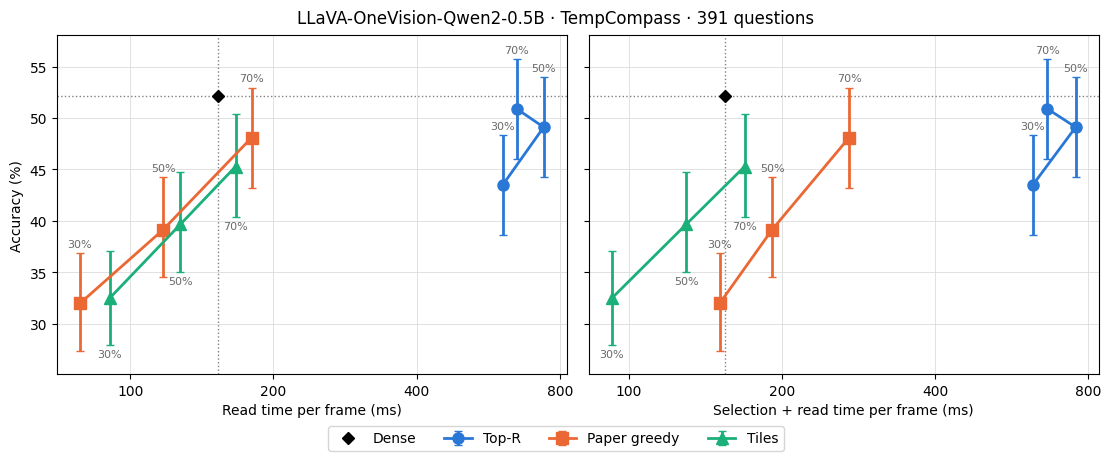

In [12]:
fig, (left, right) = plt.subplots(
    1, 2,
    figsize = (11, 4.5),
    sharey  = True,
    layout  = "constrained",
)

draw_panel(left,  "io_ms",   "Read time per frame (ms)")
draw_panel(right, "load_ms", "Selection + read time per frame (ms)")

left.set_ylabel("Accuracy (%)")

handles, labels = left.get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4)

questions = answers.question_id.nunique()
fig.suptitle(f"LLaVA-OneVision-Qwen2-0.5B · TempCompass · {questions} questions")

plt.show()